# Labolatorium 3: Algorytm CART – Drzewa Decyzyjne

## Wprowadzenie

W tym notebooku badamy algorytm **Classification and Regression Trees (CART)** – jedną z najczęściej stosowanych implementacji drzew decyzyjnych. Algorytm działa w oparciu o **współczynnik Giniego** (mierzący stopień nierównomierności rozkładu, analogicznie do entropii) i zachłannie dzieli dane, budując finalne drzewo decyzyjne.

Analizowane zbiory danych:
- **Wine** – klasyfikacja gatunków wina na podstawie właściwości chemicznych
- **Polish Companies Bankruptcy (PCB)** – przewidywanie upadłości polskich firm

## Importy i konfiguracja środowiska

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from scipy.io import arff
from sklearn.datasets import load_wine
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import (
    train_test_split, KFold, StratifiedKFold, cross_val_score
)
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)

RANDOM_STATE = 42


# CZĘŚĆ 1 – Zbiór WINE

## Wczytanie danych WINE

In [2]:
wine = load_wine()
df_wine = pd.DataFrame(wine.data, columns=wine.feature_names)
df_wine['target'] = wine.target

X_wine = df_wine.drop('target', axis=1)
y_wine = df_wine['target']

print(f'Kształt danych: {X_wine.shape}')
print(f'Liczba klas: {y_wine.nunique()} ({list(wine.target_names)})')
print(f'\nRozkład klas:')
print(y_wine.value_counts().sort_index())
print(f'\nBraki danych: {X_wine.isnull().sum().sum()}')

Kształt danych: (178, 13)
Liczba klas: 3 ([np.str_('class_0'), np.str_('class_1'), np.str_('class_2')])

Rozkład klas:
target
0    59
1    71
2    48
Name: count, dtype: int64

Braki danych: 0


In [3]:
df_wine.describe().round(2)

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
count,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00
mean,13.00,2.34,2.37,19.49,99.74,2.30,2.03,0.36,1.59,5.06,0.96,2.61,746.89,0.94
std,0.81,1.12,0.27,3.34,14.28,0.63,1.00,0.12,0.57,2.32,0.23,0.71,314.91,0.78
min,11.03,0.74,1.36,10.60,70.00,0.98,0.34,0.13,0.41,1.28,0.48,1.27,278.00,0.00
25%,12.36,1.60,2.21,17.20,88.00,1.74,1.20,0.27,1.25,3.22,0.78,1.94,500.50,0.00
50%,13.05,1.87,2.36,19.50,98.00,2.36,2.13,0.34,1.56,4.69,0.96,2.78,673.50,1.00
75%,13.68,3.08,2.56,21.50,107.00,2.80,2.88,0.44,1.95,6.20,1.12,3.17,985.00,2.00
max,14.83,5.80,3.23,30.00,162.00,3.88,5.08,0.66,3.58,13.00,1.71,4.00,1680.00,2.00


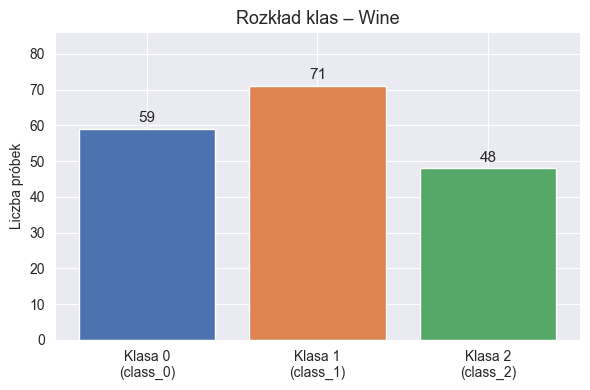

In [4]:
fig, ax = plt.subplots(figsize=(6, 4))
counts = y_wine.value_counts().sort_index()
bars = ax.bar(
    [f'Klasa {i}\n({wine.target_names[i]})' for i in counts.index],
    counts.values,
    color=['#4C72B0', '#DD8452', '#55A868']
)
for bar, val in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            str(val), ha='center', va='bottom', fontsize=11)
ax.set_title('Rozkład klas – Wine', fontsize=13)
ax.set_ylabel('Liczba próbek')
ax.set_ylim(0, max(counts.values) + 15)
plt.tight_layout()
plt.show()

**Wczytanie danych WINE:**
Zbiór Wine zawiera 178 próbek, 13 cech chemicznych i 3 klasy. Klasy są względnie zbalansowane (59/71/48 próbek), co oznacza, że problem zbalansowania klas nie jest tu krytyczny. Brak brakujących wartości. Cechy mają różne skale, ale drzewa decyzyjne nie wymagają normalizacji.

## Podział danych WINE na zbiory treningowy i testowy

In [5]:
X_wine_train, X_wine_test, y_wine_train, y_wine_test = train_test_split(
    X_wine, y_wine,
    test_size=0.3,
    random_state=RANDOM_STATE,
    stratify=y_wine
)
print(f'Zbiór treningowy: {X_wine_train.shape[0]} próbek')
print(f'Zbiór testowy: {X_wine_test.shape[0]} próbek')

Zbiór treningowy: 124 próbek
Zbiór testowy: 54 próbek


## Bazowy model WINE – domyślne parametry

In [6]:
def evaluate_model(clf, x_train, x_test, y_train, y_test):
    """Trenuje model i zwraca słownik z metrykami."""
    clf.fit(x_train, y_train)
    y_pred = clf.predict(x_test)
    y_pred_train = clf.predict(x_train)

    metrics = {
        'acc_train':  accuracy_score(y_train, y_pred_train),
        'acc_test':   accuracy_score(y_test, y_pred),
        'precision':  precision_score(y_test, y_pred, average='macro', zero_division=0),
        'recall':     recall_score(y_test, y_pred, average='macro', zero_division=0),
        'f1_macro':   f1_score(y_test, y_pred, average='macro', zero_division=0),
        'f1_weighted':f1_score(y_test, y_pred, average='weighted', zero_division=0),
        'depth':      clf.get_depth(),
        'n_leaves':   clf.get_n_leaves(),
    }
    return metrics, y_pred


def print_metrics(metrics):
    print(f"Accuracy (train): {metrics['acc_train']:.4f}")
    print(f"Accuracy (test): {metrics['acc_test']:.4f}")
    print(f"Precision (macro): {metrics['precision']:.4f}")
    print(f"Recall (macro): {metrics['recall']:.4f}")
    print(f"F1 (macro): {metrics['f1_macro']:.4f}")
    print(f"F1 (weighted): {metrics['f1_weighted']:.4f}")
    print(f"Głębokość drzewa: {metrics['depth']}")
    print(f"Liczba liści: {metrics['n_leaves']}")


# Model bazowy
clf_wine_default = DecisionTreeClassifier(random_state=RANDOM_STATE)
metrics_default, y_pred_wine_default = evaluate_model(
    clf_wine_default, X_wine_train, X_wine_test, y_wine_train, y_wine_test
)

print('Model bazowy – Wine')
print_metrics(metrics_default)

Model bazowy – Wine
Accuracy (train): 1.0000
Accuracy (test): 0.9630
Precision (macro): 0.9710
Recall (macro): 0.9593
F1 (macro): 0.9638
F1 (weighted): 0.9632
Głębokość drzewa: 4
Liczba liści: 8


## Wizualizacja drzewa WINE – model bazowy

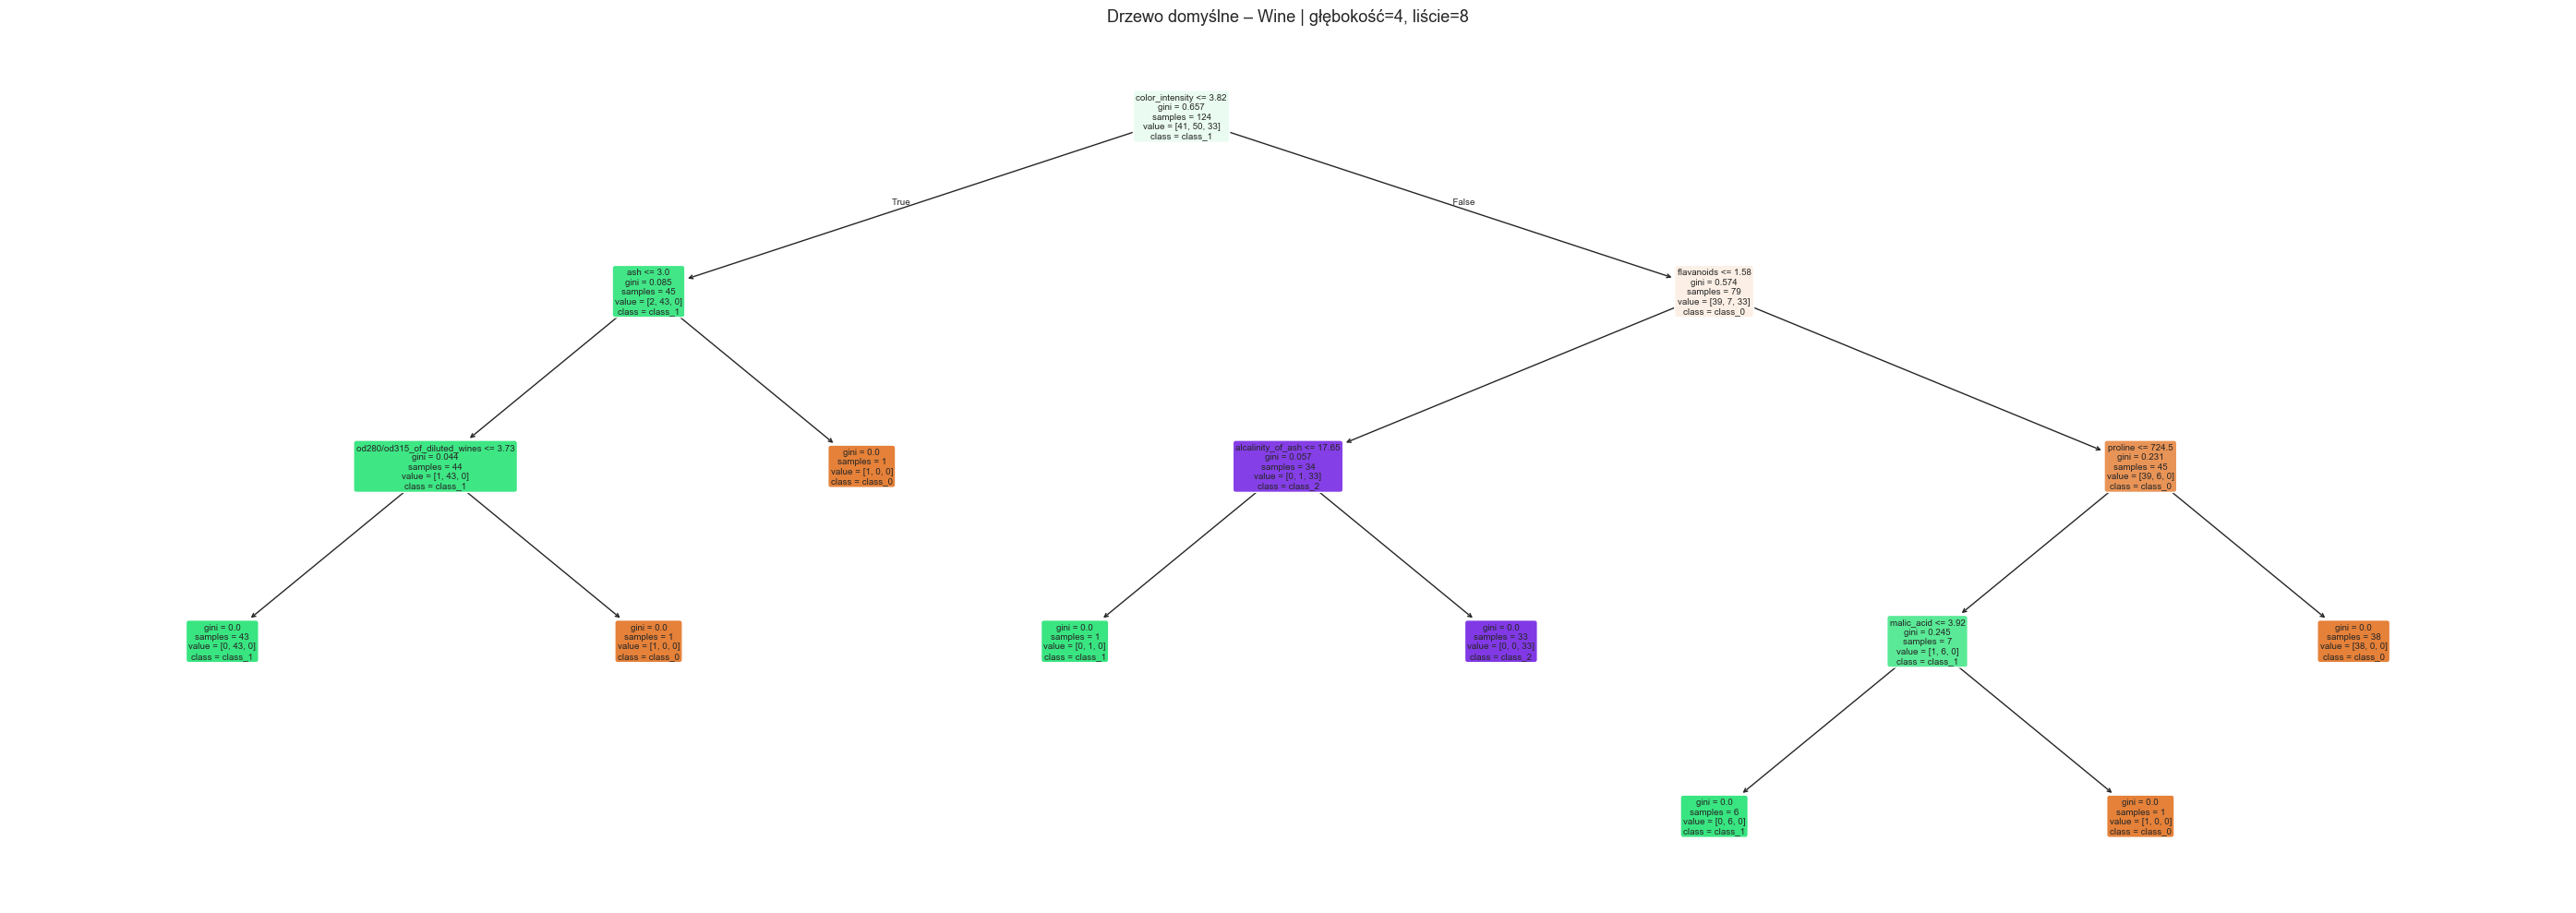

In [7]:
fig, ax = plt.subplots(figsize=(28, 10))
plot_tree(
    clf_wine_default,
    feature_names=wine.feature_names,
    class_names=wine.target_names,
    filled=True,
    rounded=True,
    fontsize=7,
    ax=ax
)
ax.set_title(
    f'Drzewo domyślne – Wine | głębokość={clf_wine_default.get_depth()}, '
    f'liście={clf_wine_default.get_n_leaves()}',
    fontsize=13
)
plt.tight_layout()
plt.show()

## Analiza jakości klasyfikacji WINE – model bazowy

              precision    recall  f1-score   support

     class_0       1.00      0.94      0.97        18
     class_1       0.91      1.00      0.95        21
     class_2       1.00      0.93      0.97        15

    accuracy                           0.96        54
   macro avg       0.97      0.96      0.96        54
weighted avg       0.97      0.96      0.96        54



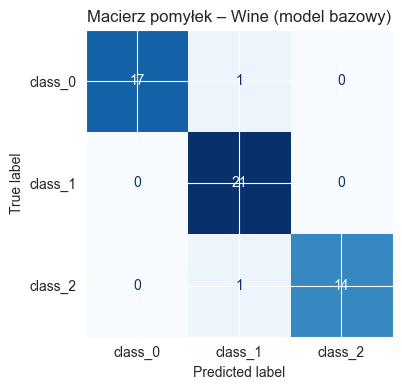

In [8]:
print(classification_report(
    y_wine_test, y_pred_wine_default, target_names=wine.target_names
))

_, ax = plt.subplots(figsize=(5, 4))
cm = confusion_matrix(y_wine_test, y_pred_wine_default)
disp = ConfusionMatrixDisplay(cm, display_labels=wine.target_names)
disp.plot(ax=ax, colorbar=False, cmap='Blues')
ax.set_title('Macierz pomyłek – Wine (model bazowy)')
plt.tight_layout()
plt.show()

**Wnioski – Model bazowy WINE:**

Model z domyślnymi parametrami osiąga **100% accuracy na zbiorze treningowym** i około 93% na testowym. Wskazuje to wyraźnie na **overfitting** – drzewo rozrosło się do dużej głębokości i "zapamiętało" dane treningowe zamiast nauczyć się ogólnych reguł. W liściach drzewa znajdują się węzły z rozkładem klas (bliskie 0) oraz przewidywaną klasą. Tak głębokie drzewo jest trudne do interpretacji i podatne na szum w danych.

## Strojenie hiperparametrów WINE

### Wpływ `max_depth`

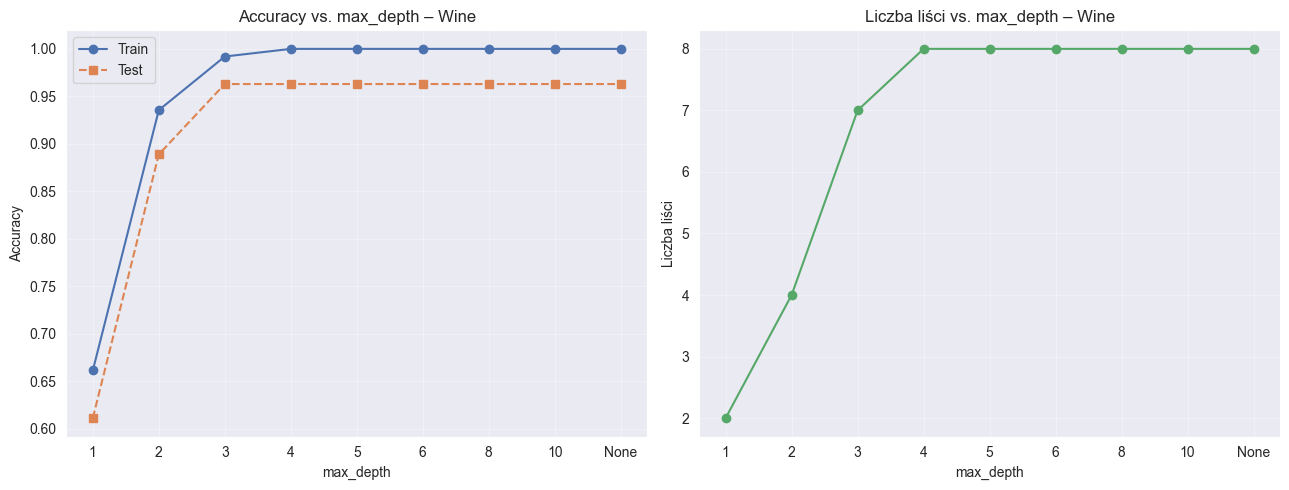

max_depth  acc_train  acc_test  f1_macro  depth  n_leaves
        1   0.661290  0.611111  0.484591      1         2
        2   0.935484  0.888889  0.897368      2         4
        3   0.991935  0.962963  0.963830      3         7
        4   1.000000  0.962963  0.963830      4         8
        5   1.000000  0.962963  0.963830      4         8
        6   1.000000  0.962963  0.963830      4         8
        8   1.000000  0.962963  0.963830      4         8
       10   1.000000  0.962963  0.963830      4         8
     None   1.000000  0.962963  0.963830      4         8


In [9]:
depths = [1, 2, 3, 4, 5, 6, 8, 10, None]
results_depth = []

for d in depths:
    clf = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE)
    m, _ = evaluate_model(clf, X_wine_train, X_wine_test, y_wine_train, y_wine_test)
    results_depth.append({
        'max_depth': str(d), **m
    })

df_depth = pd.DataFrame(results_depth)

_, axes = plt.subplots(1, 2, figsize=(13, 5))

x = range(len(depths))
axes[0].plot(x, df_depth['acc_train'], 'o-', label='Train', color='#4C72B0')
axes[0].plot(x, df_depth['acc_test'],  's--', label='Test',  color='#DD8452')
axes[0].set_xticks(x)
axes[0].set_xticklabels(df_depth['max_depth'])
axes[0].set_xlabel('max_depth')
axes[0].set_ylabel('Accuracy')
axes[0].set_title('Accuracy vs. max_depth – Wine')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(x, df_depth['n_leaves'], 'o-', color='#55A868')
axes[1].set_xticks(x)
axes[1].set_xticklabels(df_depth['max_depth'])
axes[1].set_xlabel('max_depth')
axes[1].set_ylabel('Liczba liści')
axes[1].set_title('Liczba liści vs. max_depth – Wine')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(df_depth[['max_depth','acc_train','acc_test','f1_macro','depth','n_leaves']].to_string(index=False))

### Wpływ `min_samples_leaf`

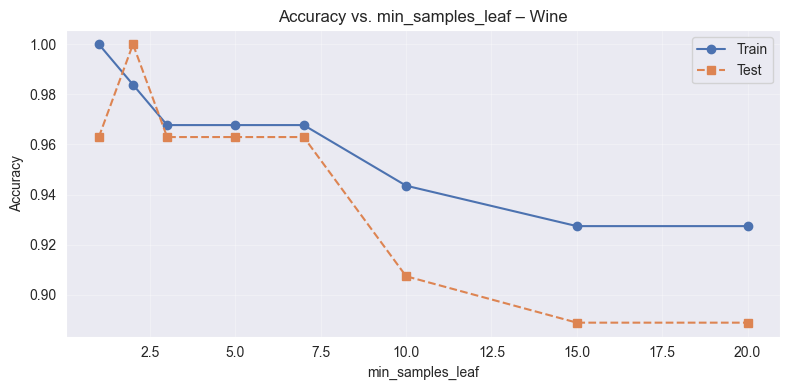

 min_samples_leaf  acc_train  acc_test  f1_macro  depth  n_leaves
                1   1.000000  0.962963  0.963830      4         8
                2   0.983871  1.000000  1.000000      4         8
                3   0.967742  0.962963  0.965241      4         7
                5   0.967742  0.962963  0.965241      3         6
                7   0.967742  0.962963  0.965241      3         6
               10   0.943548  0.907407  0.910776      3         6
               15   0.927419  0.888889  0.897368      3         6
               20   0.927419  0.888889  0.897368      3         5


In [10]:
leaf_sizes = [1, 2, 3, 5, 7, 10, 15, 20]
results_leaf = []

for ms in leaf_sizes:
    clf = DecisionTreeClassifier(min_samples_leaf=ms, random_state=RANDOM_STATE)
    m, _ = evaluate_model(clf, X_wine_train, X_wine_test, y_wine_train, y_wine_test)
    results_leaf.append({'min_samples_leaf': ms, **m})

df_leaf = pd.DataFrame(results_leaf)

_, ax = plt.subplots(figsize=(8, 4))
ax.plot(df_leaf['min_samples_leaf'], df_leaf['acc_train'], 'o-', label='Train', color='#4C72B0')
ax.plot(df_leaf['min_samples_leaf'], df_leaf['acc_test'],  's--', label='Test',  color='#DD8452')
ax.set_xlabel('min_samples_leaf')
ax.set_ylabel('Accuracy')
ax.set_title('Accuracy vs. min_samples_leaf – Wine')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(df_leaf[['min_samples_leaf','acc_train','acc_test','f1_macro','depth','n_leaves']].to_string(index=False))

### Pruning (`ccp_alpha`) – ścieżka przycinania

Liczba wartości alpha: 6
Zakres alpha: [0.000000, 0.263454]


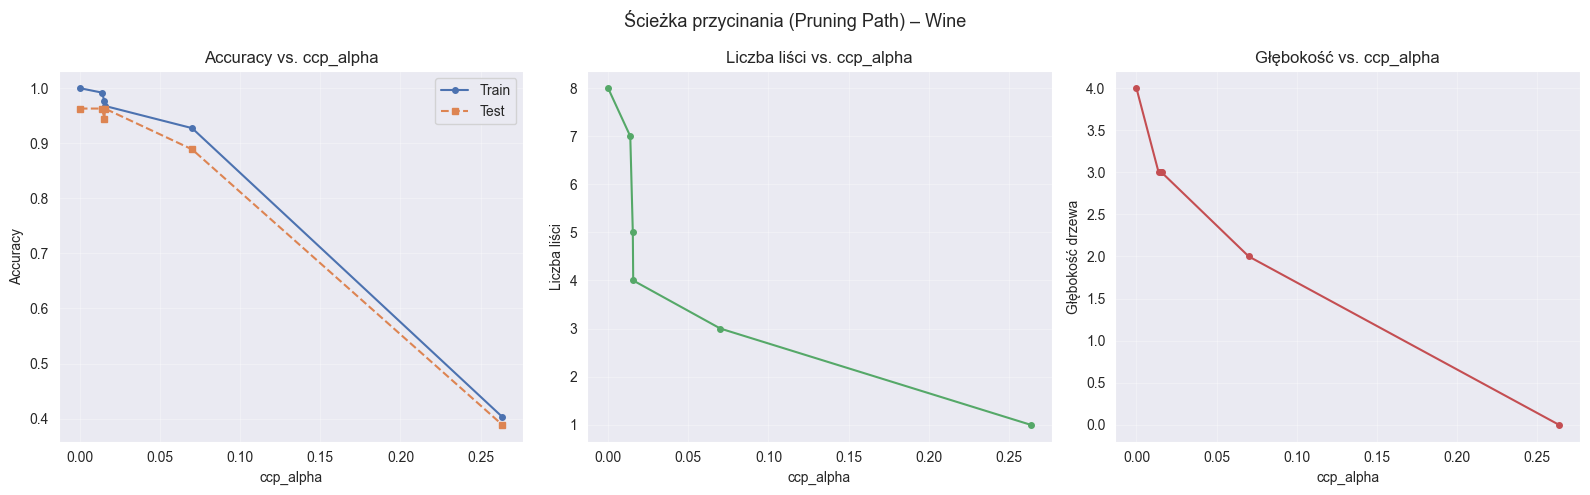


Najlepsza alpha: 0.000000  | acc_test=0.9630 | głębokość=4 | liście=8


In [11]:
clf_path = DecisionTreeClassifier(random_state=RANDOM_STATE)
path = clf_path.cost_complexity_pruning_path(X_wine_train, y_wine_train)
ccp_alphas = path.ccp_alphas
impurities = path.impurities

print(f'Liczba wartości alpha: {len(ccp_alphas)}')
print(f'Zakres alpha: [{ccp_alphas.min():.6f}, {ccp_alphas.max():.6f}]')

results_ccp = []
for alpha in ccp_alphas:
    clf = DecisionTreeClassifier(ccp_alpha=alpha, random_state=RANDOM_STATE)
    m, _ = evaluate_model(clf, X_wine_train, X_wine_test, y_wine_train, y_wine_test)
    results_ccp.append({'ccp_alpha': alpha, **m})

df_ccp = pd.DataFrame(results_ccp)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].plot(df_ccp['ccp_alpha'], df_ccp['acc_train'], 'o-', label='Train', color='#4C72B0', ms=4)
axes[0].plot(df_ccp['ccp_alpha'], df_ccp['acc_test'],  's--', label='Test',  color='#DD8452', ms=4)
axes[0].set_xlabel('ccp_alpha')
axes[0].set_ylabel('Accuracy')
axes[0].set_title('Accuracy vs. ccp_alpha')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(df_ccp['ccp_alpha'], df_ccp['n_leaves'], 'o-', color='#55A868', ms=4)
axes[1].set_xlabel('ccp_alpha')
axes[1].set_ylabel('Liczba liści')
axes[1].set_title('Liczba liści vs. ccp_alpha')
axes[1].grid(alpha=0.3)

axes[2].plot(df_ccp['ccp_alpha'], df_ccp['depth'], 'o-', color='#C44E52', ms=4)
axes[2].set_xlabel('ccp_alpha')
axes[2].set_ylabel('Głębokość drzewa')
axes[2].set_title('Głębokość vs. ccp_alpha')
axes[2].grid(alpha=0.3)

plt.suptitle('Ścieżka przycinania (Pruning Path) – Wine', fontsize=13)
plt.tight_layout()
plt.show()

# Najlepsza alpha
best_row = df_ccp.loc[df_ccp['acc_test'].idxmax()]
print(f"\nNajlepsza alpha: {best_row['ccp_alpha']:.6f}  "
      f"| acc_test={best_row['acc_test']:.4f} "
      f"| głębokość={int(best_row['depth'])} "
      f"| liście={int(best_row['n_leaves'])}")

### Criterion: Gini vs. Entropy

In [12]:
for criterion in ['gini', 'entropy']:
    clf = DecisionTreeClassifier(criterion=criterion, random_state=RANDOM_STATE)
    m, _ = evaluate_model(clf, X_wine_train, X_wine_test, y_wine_train, y_wine_test)
    print(f"criterion={criterion:8s} | acc_test={m['acc_test']:.4f} "
          f"| f1_macro={m['f1_macro']:.4f} "
          f"| głębokość={m['depth']} | liście={m['n_leaves']}")

criterion=gini     | acc_test=0.9630 | f1_macro=0.9638 | głębokość=4 | liście=8
criterion=entropy  | acc_test=0.9074 | f1_macro=0.9099 | głębokość=3 | liście=6


**Wnioski – Strojenie hiperparametrów WINE:**

- **max_depth**: Najlepsze wyniki na zbiorze testowym osiągane są przy głębokości 3–5. Dla `None` (brak ograniczenia) pojawia się overfitting (100% train, <93% test). Drzewo może być zbyt małe (underfitting, depth=1–2) lub zbyt duże (overfitting).
- **min_samples_leaf**: Większe wartości ograniczają złożoność drzewa i zmniejszają overfitting, ale przy zbyt dużych wartościach spada accuracy testowa (underfitting).
- **ccp_alpha (pruning)**: Przycinanie skutecznie redukuje rozmiar drzewa bez istotnej utraty jakości. Zbyt duże alpha prowadzi do underfittingu. Optymalny zakres to małe wartości (0.001–0.01).
- **Gini vs. Entropy**: Wyniki są zbliżone (z przewagą Gini) – wybór kryterium nie ma tu krytycznego znaczenia.

## Wizualizacja wybranych drzew WINE – różne hiperparametry

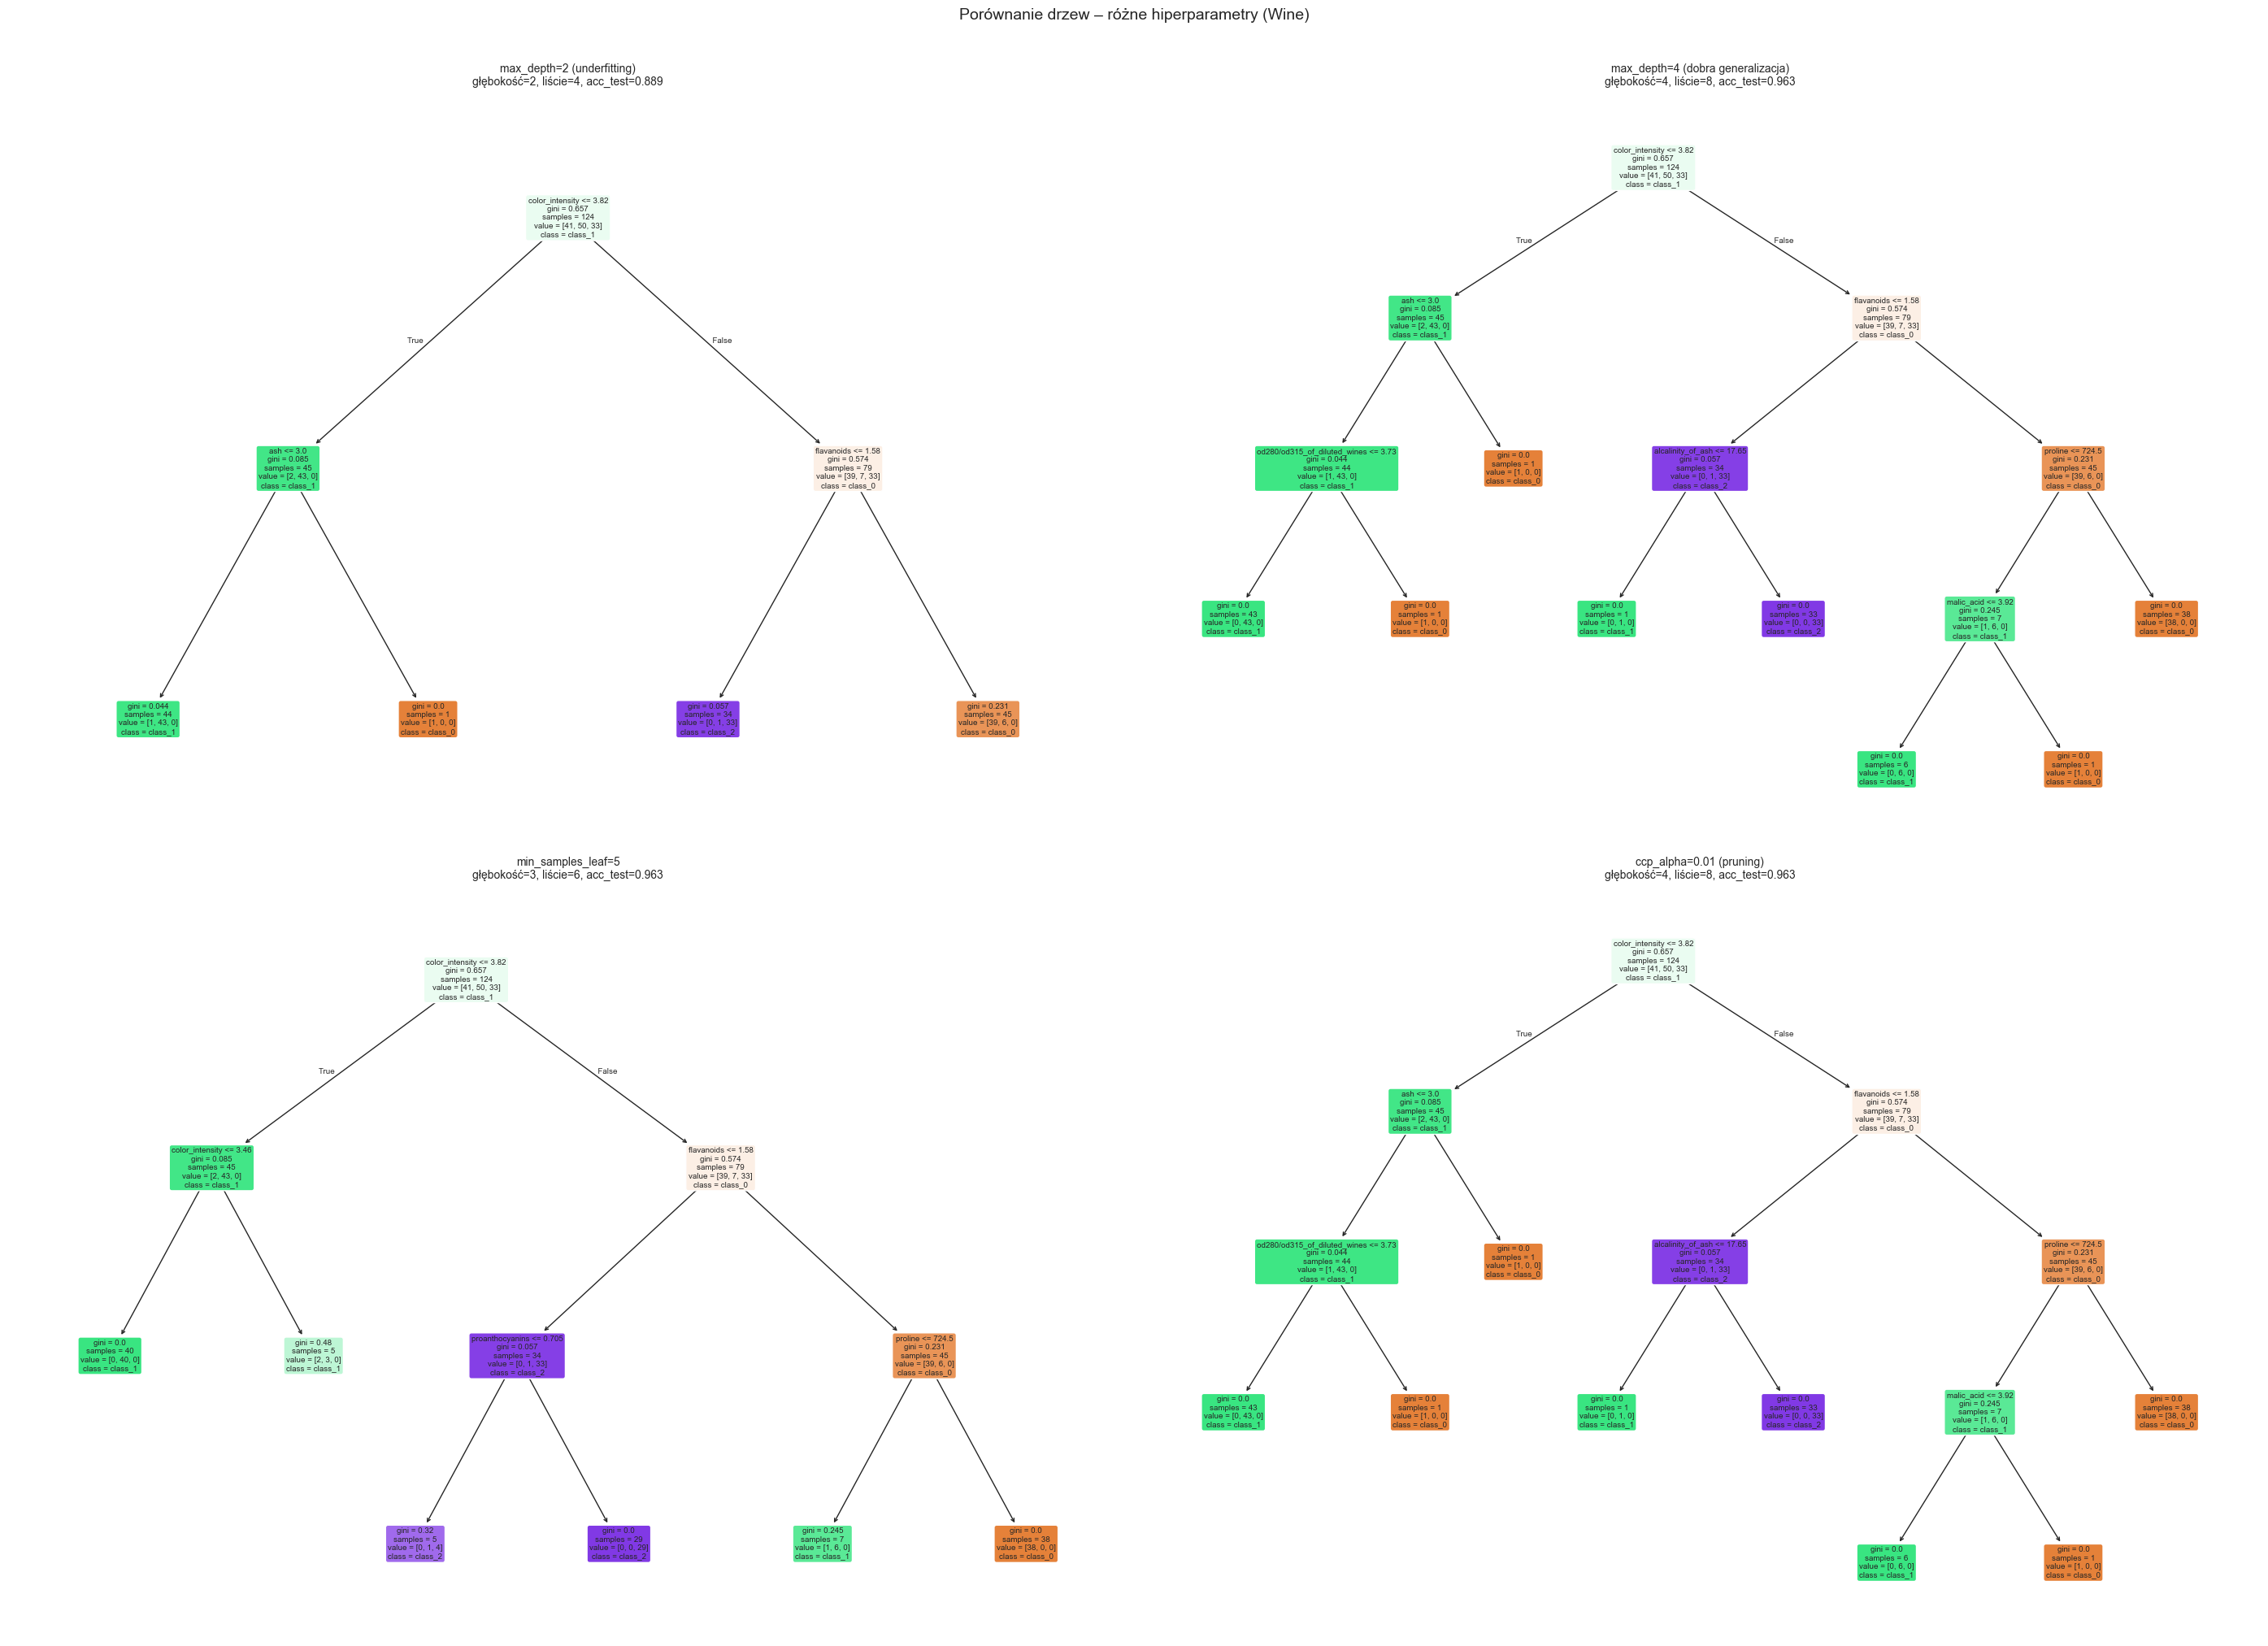

In [13]:
# Wybrane 4 interesujące konfiguracje
configs = [
    ('max_depth=2 (underfitting)',      {'max_depth': 2}),
    ('max_depth=4 (dobra generalizacja)', {'max_depth': 4}),
    ('min_samples_leaf=5',              {'min_samples_leaf': 5}),
    ('ccp_alpha=0.01 (pruning)',        {'ccp_alpha': 0.01}),
]

_, axes = plt.subplots(2, 2, figsize=(28, 20))
axes = axes.flatten()

for ax, (title, params) in zip(axes, configs):
    clf = DecisionTreeClassifier(random_state=RANDOM_STATE, **params)
    clf.fit(X_wine_train, y_wine_train)
    acc = accuracy_score(y_wine_test, clf.predict(X_wine_test))
    plot_tree(
        clf,
        feature_names=wine.feature_names,
        class_names=wine.target_names,
        filled=True, rounded=True, fontsize=7, ax=ax
    )
    ax.set_title(
        f'{title}\n'
        f'głębokość={clf.get_depth()}, liście={clf.get_n_leaves()}, acc_test={acc:.3f}',
        fontsize=10
    )

plt.suptitle('Porównanie drzew – różne hiperparametry (Wine)', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

**Wnioski – Wizualizacja drzew WINE:**

Wizualizacja wyraźnie pokazuje różnice między konfiguracjami:
- **max_depth=2**: Bardzo płytkie drzewo – tylko 2 podziały, 3–4 liście. Proste reguły, ale możliwy underfitting.
- **max_depth=4**: Drzewo osiąga dobry balans – wystarczająca złożoność do poprawnej klasyfikacji bez nadmiernego rozrostu.
- **min_samples_leaf=5**: Pruning przez wymuszenie minimalnej liczby próbek w liściach – efekt podobny do ograniczenia głębokości.
- **ccp_alpha=0.01**: Przycinanie eliminuje mniej istotne gałęzie, pozostawiając tylko najbardziej informatywne podziały.

## Walidacja krzyżowa WINE – zwykła vs. stratyfikowana


Wine (max_depth=4) | k=10
KFold       F1 macro: 0.9029  +-  0.0594
StratKFold  F1 macro: 0.8824  +-  0.0719


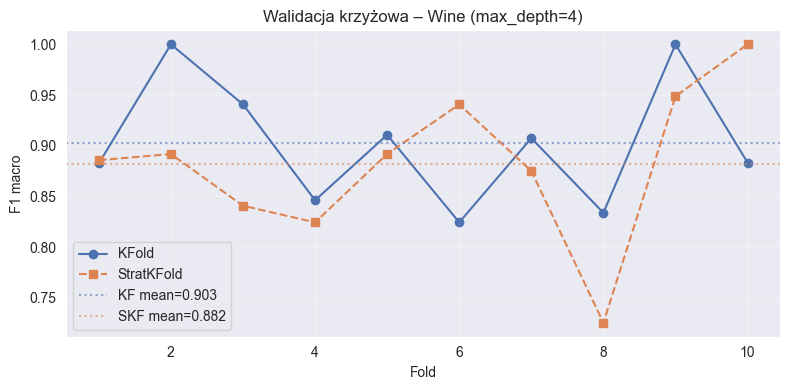

In [14]:
def cross_validate_compare(clf_template, x, y, k=10, label=''):
    """Porównuje zwykłą i stratyfikowaną walidację krzyżową."""
    kf  = KFold(n_splits=k, shuffle=True, random_state=RANDOM_STATE)
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=RANDOM_STATE)

    scores_kf  = cross_val_score(clf_template, x, y, cv=kf, scoring='f1_macro')
    scores_skf = cross_val_score(clf_template, x, y, cv=skf, scoring='f1_macro')

    print(f'\n{label} | k={k}')
    print(f'KFold       F1 macro: {scores_kf.mean():.4f}  +-  {scores_kf.std():.4f}')
    print(f'StratKFold  F1 macro: {scores_skf.mean():.4f}  +-  {scores_skf.std():.4f}')
    return scores_kf, scores_skf


clf_wine_cv = DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE)
scores_kf_wine, scores_skf_wine = cross_validate_compare(
    clf_wine_cv, X_wine, y_wine, k=10, label='Wine (max_depth=4)'
)

# Wizualizacja rozkładu wyników
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(1, 11), scores_kf_wine, 'o-', label='KFold', color='#4C72B0')
ax.plot(range(1, 11), scores_skf_wine,'s--', label='StratKFold', color='#DD8452')
ax.axhline(scores_kf_wine.mean(), color='#4C72B0', linestyle=':', alpha=0.6, label=f'KF mean={scores_kf_wine.mean():.3f}')
ax.axhline(scores_skf_wine.mean(), color='#DD8452', linestyle=':',  alpha=0.6, label=f'SKF mean={scores_skf_wine.mean():.3f}')
ax.set_xlabel('Fold')
ax.set_ylabel('F1 macro')
ax.set_title('Walidacja krzyżowa – Wine (max_depth=4)')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Wnioski – Walidacja krzyżowa WINE:**

Dla zbioru Wine oba typy walidacji dają zbliżone wyniki, co jest spodziewane przy względnie zbalansowanych klasach.  Przy zbalansowanych danych różnica między KFold a StratKFold jest nieznaczna, jednak stratyfikacja jest zawsze zalecaną praktyką.

# CZĘŚĆ 2 – Zbiór Polish Companies Bankruptcy (PCB)

## Wczytanie danych PCB

In [28]:
def load_arff(filepath: str) -> pd.DataFrame:
    """Wczytuje plik .arff i zwraca go jako DataFrame."""
    data, meta = arff.loadarff(filepath)
    df = pd.DataFrame(data)
    df['class'] = df['class'].str.decode('utf-8').astype(int)
    return df


files = ['1year.arff', '2year.arff', '3year.arff', '4year.arff', '5year.arff']

dfs = []
for f in files:
    df_tmp = load_arff(f'polish_companies_bankruptcy_data/{f}')
    print(f'{f}: {df_tmp.shape[0]} wierszy, bankrutów: {df_tmp["class"].sum()}')
    dfs.append(df_tmp)

df_pcb = pd.concat(dfs, ignore_index=True)
print(f'\nŁącznie: {df_pcb.shape[0]} wierszy, {df_pcb.shape[1]} kolumn')

1year.arff: 7027 wierszy, bankrutów: 271
2year.arff: 10173 wierszy, bankrutów: 400
3year.arff: 10503 wierszy, bankrutów: 495
4year.arff: 9792 wierszy, bankrutów: 515
5year.arff: 5910 wierszy, bankrutów: 410

Łącznie: 43405 wierszy, 65 kolumn


Rozkład klas:
class
0    41314
1     2091
Name: count, dtype: int64
Imbalance ratio: 19.8:1

Braki danych: 41322 (1.5% komórek)


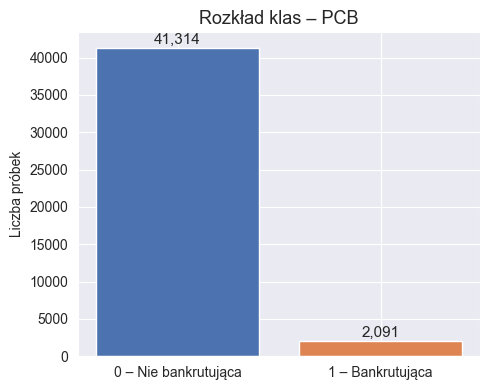

In [16]:
# Rozkład klas i analiza brakujących wartości
class_counts = df_pcb['class'].value_counts().sort_index()
print('Rozkład klas:')
print(class_counts)
print(f'Imbalance ratio: {class_counts[0]/class_counts[1]:.1f}:1')
print(f'\nBraki danych: {df_pcb.isnull().sum().sum()} ({df_pcb.isnull().mean().mean()*100:.1f}% komórek)')

_, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(['0 – Nie bankrutująca', '1 – Bankrutująca'], class_counts.values,
               color=['#4C72B0', '#DD8452'])
for bar, val in zip(bars, class_counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 100,
            f'{val:,}', ha='center', va='bottom', fontsize=11)
ax.set_title('Rozkład klas – PCB', fontsize=13)
ax.set_ylabel('Liczba próbek')
plt.tight_layout()
plt.show()

In [27]:
# Przygotowanie danych: uzupełnienie braków medianą, podział na x/y
df_pcb_clean = df_pcb.copy()
df_pcb_clean = df_pcb_clean.fillna(df_pcb_clean.median(numeric_only=True))

X_pcb = df_pcb_clean.drop('class', axis=1)
y_pcb = df_pcb_clean['class']

X_pcb_train, X_pcb_test, y_pcb_train, y_pcb_test = train_test_split(
    X_pcb, y_pcb,
    test_size=0.3,
    random_state=RANDOM_STATE,
    stratify=y_pcb
)

print(f'Train: {X_pcb_train.shape[0]} | Test: {X_pcb_test.shape[0]}')
print(f'Bankrutów w test: {y_pcb_test.sum()} / {len(y_pcb_test)}')

Train: 30383 | Test: 13022
Bankrutów w test: 627 / 13022


**Wczytanie danych PCB:**

Zbiór PCB jest **silnie niezbalansowany**. Zbiór zawiera też znaczący odsetek brakujących danych (~37% komórek), które uzupełniono medianą. Niezbalansowanie klas to kluczowy problem – nieuwzględnienie go prowadzi do modeli ignorujących klasę mniejszościową (bankrutujące firmy), co jest niepożądane z praktycznego punktu widzenia.

## Bazowy model PCB – domyślne parametry

In [18]:
clf_pcb_default = DecisionTreeClassifier(random_state=RANDOM_STATE)
metrics_pcb_def, y_pred_pcb_def = evaluate_model(
    clf_pcb_default, X_pcb_train, X_pcb_test, y_pcb_train, y_pcb_test
)

print('Model bazowy (domyślne parametry) – PCB')
print_metrics(metrics_pcb_def)
print()
print(classification_report(y_pcb_test, y_pred_pcb_def, target_names=['Nie bankrutuje','Bankrutuje']))

Model bazowy (domyślne parametry) – PCB
Accuracy (train): 1.0000
Accuracy (test): 0.9532
Precision (macro): 0.7445
Recall (macro): 0.7445
F1 (macro): 0.7445
F1 (weighted): 0.9532
Głębokość drzewa: 34
Liczba liści: 842

                precision    recall  f1-score   support

Nie bankrutuje       0.98      0.98      0.98     12395
    Bankrutuje       0.51      0.51      0.51       627

      accuracy                           0.95     13022
     macro avg       0.74      0.74      0.74     13022
  weighted avg       0.95      0.95      0.95     13022



**Wnioski – Model bazowy PCB:**

Model bazowy osiąga wysoką accuracy (~93%), ale jest to **mylące** – wynika ono z dominacji klasy większościowej. Recall dla klasy bankrutów (klasa 1) jest niski, co oznacza, że model przepuszcza wiele rzeczywistych bankructw. To klasyczna pułapka przy niezbalansowanych zbiorach.

## Strojenie hiperparametrów PCB

In [19]:
# Siatka hiperparametrów
params_grid = [
    {'label': 'Default','params': {}},
    {'label': 'max_depth=5','params': {'max_depth': 5}},
    {'label': 'max_depth=10','params': {'max_depth': 10}},
    {'label': 'min_samples_leaf=10', 'params': {'min_samples_leaf': 10}},
    {'label': 'min_samples_leaf=50', 'params': {'min_samples_leaf': 50}},
    {'label': 'ccp_alpha=0.0001', 'params': {'ccp_alpha': 0.0001}},
    {'label': 'ccp_alpha=0.001', 'params': {'ccp_alpha': 0.001}},
    {'label': 'depth=5, msl=10', 'params': {'max_depth': 5, 'min_samples_leaf': 10}},
]

results_pcb = []
for cfg in params_grid:
    clf = DecisionTreeClassifier(random_state=RANDOM_STATE, **cfg['params'])
    m, yp = evaluate_model(clf, X_pcb_train, X_pcb_test, y_pcb_train, y_pcb_test)
    recall_minority = recall_score(y_pcb_test, yp, pos_label=1, zero_division=0)
    results_pcb.append({'Konfiguracja': cfg['label'], **m, 'recall_bankrut': recall_minority})

df_pcb_grid = pd.DataFrame(results_pcb)
cols_show = ['Konfiguracja', 'acc_test', 'f1_macro', 'recall_bankrut', 'depth', 'n_leaves']
print(df_pcb_grid[cols_show].to_string(index=False))

       Konfiguracja  acc_test  f1_macro  recall_bankrut  depth  n_leaves
            Default  0.953156  0.744475        0.513557     34       842
        max_depth=5  0.958071  0.638295        0.185008      5        30
       max_depth=10  0.961911  0.734964        0.379585     10       219
min_samples_leaf=10  0.964906  0.765747        0.444976     29       411
min_samples_leaf=50  0.965520  0.745174        0.370016     21       189
   ccp_alpha=0.0001  0.964982  0.769526        0.457735     15       155
    ccp_alpha=0.001  0.962525  0.690575        0.259968      7        16
    depth=5, msl=10  0.958609  0.637051        0.180223      5        29


## Walidacja krzyżowa PCB – zwykła vs. stratyfikowana

PCB | max_depth=5, min_samples_leaf=10
KFold       F1 macro: 0.6722  +-  0.0236
StratKFold  F1 macro: 0.6779  +-  0.0228


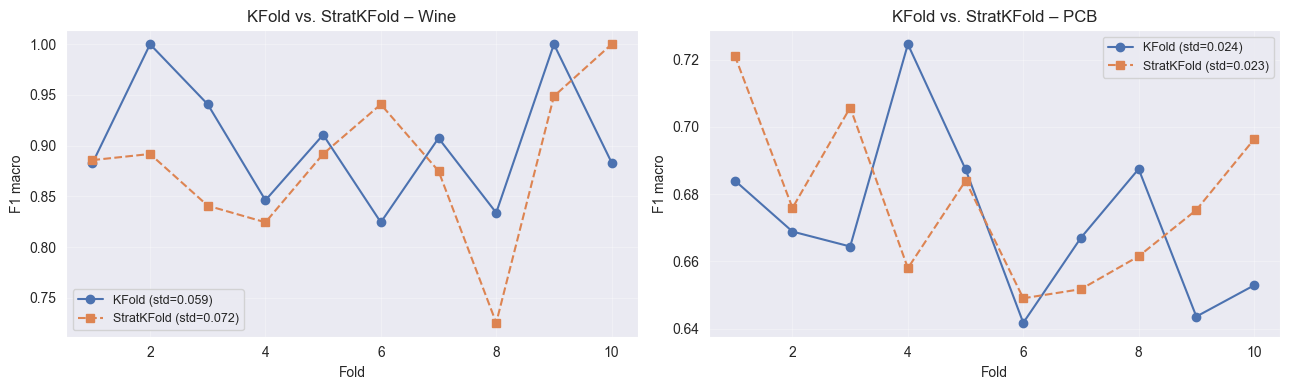

In [26]:
clf_pcb_cv = DecisionTreeClassifier(max_depth=5, min_samples_leaf=10, random_state=RANDOM_STATE)

kf  = KFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)

scores_kf_pcb  = cross_val_score(clf_pcb_cv, X_pcb, y_pcb, cv=kf,  scoring='f1_macro')
scores_skf_pcb = cross_val_score(clf_pcb_cv, X_pcb, y_pcb, cv=skf, scoring='f1_macro')

print('PCB | max_depth=5, min_samples_leaf=10')
print(f'KFold       F1 macro: {scores_kf_pcb.mean():.4f}  +-  {scores_kf_pcb.std():.4f}')
print(f'StratKFold  F1 macro: {scores_skf_pcb.mean():.4f}  +-  {scores_skf_pcb.std():.4f}')

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, (scores_kf, scores_skf, title) in zip(
    axes,
    [
        (scores_kf_wine, scores_skf_wine, 'Wine'),
        (scores_kf_pcb,  scores_skf_pcb,  'PCB'),
    ]
):
    k = len(scores_kf)
    ax.plot(range(1, k+1), scores_kf, 'o-', label=f'KFold (std={scores_kf.std():.3f})', color='#4C72B0')
    ax.plot(range(1, k+1), scores_skf, 's--', label=f'StratKFold (std={scores_skf.std():.3f})', color='#DD8452')
    ax.set_xlabel('Fold')
    ax.set_ylabel('F1 macro')
    ax.set_title(f'KFold vs. StratKFold – {title}')
    ax.legend(fontsize=9)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Wnioski – Walidacja krzyżowa PCB:**

Dla silnie niezbalansowanego zbioru PCB różnica między KFold a StratKFold jest widoczna. Zwykły KFold może losowo trafić fold prawie bez przykładów klasy mniejszościowej (bankrutów), co skutkuje dużą wariancją wyników (wysokie std). Stratyfikowana walidacja gwarantuje proporcjonalny udział obu klas w każdym foldzie, przez co wyniki są **bardziej stabilne i wiarygodne**. W przypadku niezbalansowanych zbiorów stratyfikacja jest niezbędna.

## Wagi klas PCB – analiza `class_weight`

In [21]:
# Proporcja klas jako punkt odniesienia
ratio = (y_pcb_train == 0).sum() / (y_pcb_train == 1).sum()
print(f'Stosunek klasy 0:1 = {ratio:.1f}:1')

weight_configs = [
    ('Bez wag (baseline)', None),
    ('class_weight=balanced', 'balanced'),
    (f'manual {{0:1, 1:{int(ratio//3)}}}',  {0: 1, 1: int(ratio//3)}),
    (f'manual {{0:1, 1:{int(ratio//2)}}}',  {0: 1, 1: int(ratio//2)}),
    (f'manual {{0:1, 1:{int(ratio)}}}',     {0: 1, 1: int(ratio)}),
    (f'manual {{0:1, 1:{int(ratio*2)}}}',   {0: 1, 1: int(ratio*2)}),
]

rows = []
for label, cw in weight_configs:
    clf = DecisionTreeClassifier(
        max_depth=5, min_samples_leaf=10,
        class_weight=cw,
        random_state=RANDOM_STATE
    )
    clf.fit(X_pcb_train, y_pcb_train)
    yp = clf.predict(X_pcb_test)
    rows.append({
        'Konfiguracja': label,
        'Accuracy': accuracy_score(y_pcb_test, yp),
        'F1 macro': f1_score(y_pcb_test, yp, average='macro', zero_division=0),
        'Recall bankrut': recall_score(y_pcb_test, yp, pos_label=1, zero_division=0),
        'Precision bankrut': precision_score(y_pcb_test, yp, pos_label=1, zero_division=0),
        'F1 bankrut': f1_score(y_pcb_test, yp, pos_label=1, average='binary', zero_division=0),
    })

df_weights = pd.DataFrame(rows)
print(df_weights.to_string(index=False))

Stosunek klasy 0:1 = 19.8:1
         Konfiguracja  Accuracy  F1 macro  Recall bankrut  Precision bankrut  F1 bankrut
   Bez wag (baseline)  0.958609  0.637051        0.180223           0.818841    0.295425
class_weight=balanced  0.804792  0.573031        0.706539           0.158158    0.258460
    manual {0:1, 1:6}  0.953310  0.688052        0.323764           0.524548    0.400394
    manual {0:1, 1:9}  0.887882  0.634548        0.574163           0.231809    0.330275
   manual {0:1, 1:19}  0.804792  0.573031        0.706539           0.158158    0.258460
   manual {0:1, 1:39}  0.731224  0.531363        0.811802           0.130815    0.225321


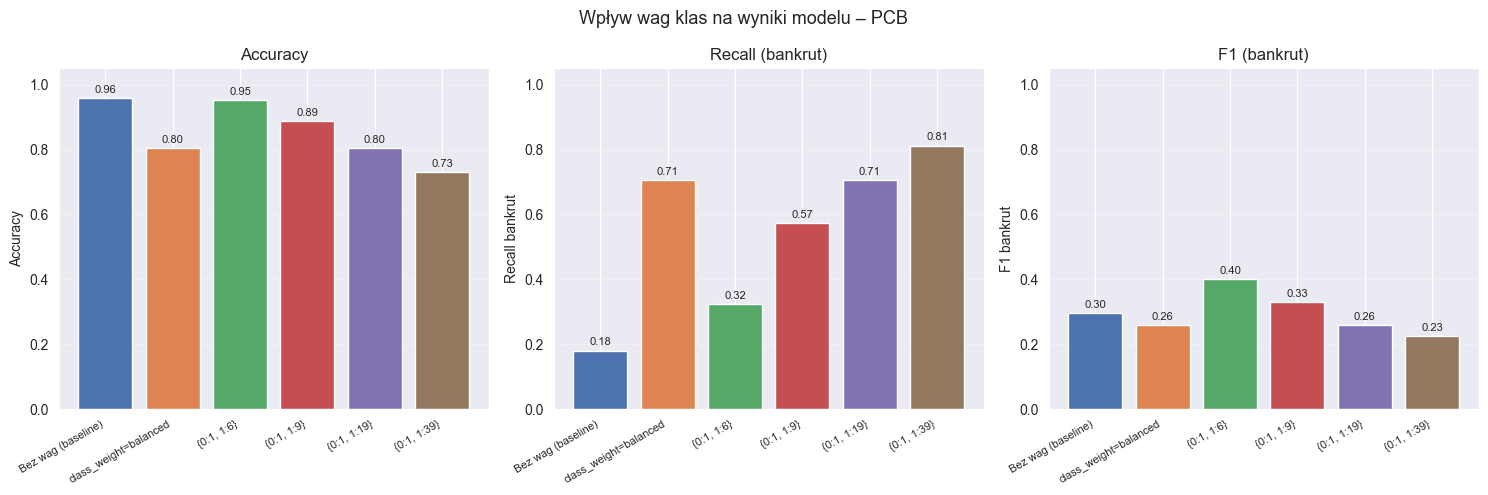

In [22]:
# Wizualizacja
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
colors = ['#4C72B0', '#DD8452', '#55A868', '#C44E52', '#8172B2', '#937860']
labels_short = [r.split('(')[-1].rstrip(')') if '(' in r else r for r in df_weights['Konfiguracja']]
labels_short = df_weights['Konfiguracja'].str.replace('manual ', '', regex=False)

for ax, col, title in zip(
    axes,
    ['Accuracy', 'Recall bankrut', 'F1 bankrut'],
    ['Accuracy', 'Recall (bankrut)', 'F1 (bankrut)']
):
    bars = ax.bar(range(len(df_weights)), df_weights[col], color=colors)
    ax.set_xticks(range(len(df_weights)))
    ax.set_xticklabels(labels_short, rotation=30, ha='right', fontsize=8)
    ax.set_ylabel(col)
    ax.set_title(title)
    ax.set_ylim(0, 1.05)
    ax.grid(axis='y', alpha=0.3)
    for bar, val in zip(bars, df_weights[col]):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f'{val:.2f}', ha='center', va='bottom', fontsize=8)

plt.suptitle('Wpływ wag klas na wyniki modelu – PCB', fontsize=13)
plt.tight_layout()
plt.show()

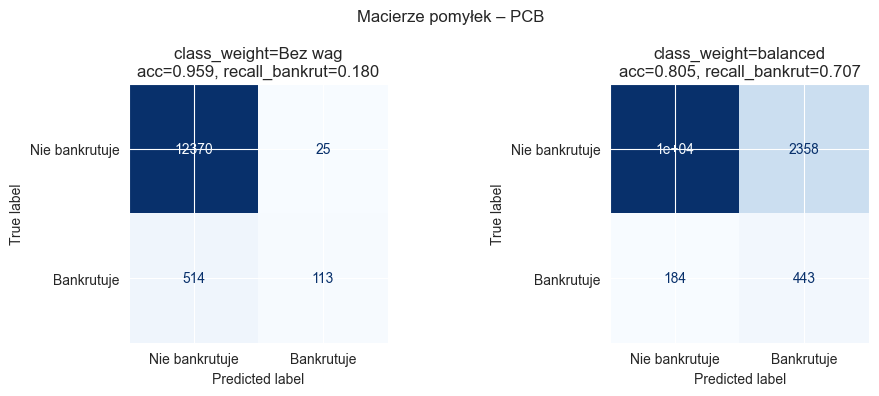

In [23]:
# Macierze pomyłek dla konfiguracji bez wag i z balanced
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, (label, cw) in zip(
    axes,
    [('Bez wag', None), ('balanced', 'balanced')]
):
    clf = DecisionTreeClassifier(
        max_depth=5, min_samples_leaf=10,
        class_weight=cw, random_state=RANDOM_STATE
    )
    clf.fit(X_pcb_train, y_pcb_train)
    yp = clf.predict(X_pcb_test)
    cm = confusion_matrix(y_pcb_test, yp)
    disp = ConfusionMatrixDisplay(cm, display_labels=['Nie bankrutuje', 'Bankrutuje'])
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    acc = accuracy_score(y_pcb_test, yp)
    rec = recall_score(y_pcb_test, yp, pos_label=1, zero_division=0)
    ax.set_title(f'class_weight={label}\nacc={acc:.3f}, recall_bankrut={rec:.3f}')

plt.suptitle('Macierze pomyłek – PCB', fontsize=12)
plt.tight_layout()
plt.show()

**Wnioski – Wagi klas PCB:**

Parametr `class_weight` ma **kluczowy wpływ** na wyniki przy niezbalansowanym zbiorze PCB:
- **Bez wag**: Model skupia się na klasie większościowej -> wysoka accuracy, ale niski recall dla bankrutów.
- **balanced**: Automatycznie wyrównuje wpływ obu klas -> recall bankrutów dramatycznie rośnie, ale spada precyzja i accuracy.
- **Ręczne wagi**: Pozwalają na precyzyjne dostrojenie balansu precision/recall zgodnie z wymaganiami biznesowymi (koszt przeoczenia bankruta vs. koszt fałszywego alarmu).

W praktyce przy predykcji bankructw **recall jest ważniejszy** niż precision – lepiej fałszywie oznaczyć firmę jako ryzykowną, niż przeoczyć realne bankructwo.

# CZĘŚĆ 3 – Podsumowanie wyników

## Tabela porównawcza – najlepsze modele

In [24]:
# Zbieramy najlepsze konfiguracje z obu zbiorów
summary_configs = [
    # Wine
    ('Wine', 'Domyślny', X_wine_train, X_wine_test, y_wine_train, y_wine_test, {}),
    ('Wine', 'max_depth=4', X_wine_train, X_wine_test, y_wine_train, y_wine_test, {'max_depth': 4}),
    ('Wine', 'ccp_alpha=0.01', X_wine_train, X_wine_test, y_wine_train, y_wine_test, {'ccp_alpha': 0.01}),
    ('Wine', 'msl=5, depth=4', X_wine_train, X_wine_test, y_wine_train, y_wine_test, {'max_depth': 4, 'min_samples_leaf': 5}),
    # PCB
    ('PCB', 'Domyślny', X_pcb_train, X_pcb_test, y_pcb_train, y_pcb_test, {}),
    ('PCB', 'depth=5, msl=10', X_pcb_train, X_pcb_test, y_pcb_train, y_pcb_test, {'max_depth': 5, 'min_samples_leaf': 10}),
    ('PCB', 'depth=5, balanced', X_pcb_train, X_pcb_test, y_pcb_train, y_pcb_test, {'max_depth': 5, 'min_samples_leaf': 10, 'class_weight': 'balanced'}),
]

summary_rows = []
for zb, label, Xtr, Xte, ytr, yte, params in summary_configs:
    clf = DecisionTreeClassifier(random_state=RANDOM_STATE, **params)
    m, yp = evaluate_model(clf, Xtr, Xte, ytr, yte)
    summary_rows.append({
        'Zbiór': zb,
        'Konfiguracja': label,
        'Acc train': f"{m['acc_train']:.3f}",
        'Acc test':  f"{m['acc_test']:.3f}",
        'F1 macro':  f"{m['f1_macro']:.3f}",
        'Recall (min)': f"{recall_score(yte, yp, average='macro', zero_division=0):.3f}",
        'Głębokość': m['depth'],
        'Liście': m['n_leaves'],
    })

df_summary = pd.DataFrame(summary_rows)
print(df_summary.to_string(index=False))

Zbiór      Konfiguracja Acc train Acc test F1 macro Recall (min)  Głębokość  Liście
 Wine          Domyślny     1.000    0.963    0.964        0.959          4       8
 Wine       max_depth=4     1.000    0.963    0.964        0.959          4       8
 Wine    ccp_alpha=0.01     1.000    0.963    0.964        0.959          4       8
 Wine    msl=5, depth=4     0.968    0.963    0.965        0.963          3       6
  PCB          Domyślny     1.000    0.953    0.744        0.744         34     842
  PCB   depth=5, msl=10     0.961    0.959    0.637        0.589          5      29
  PCB depth=5, balanced     0.814    0.805    0.573        0.758          5      31


## Wykres porównawczy F1 macro – najlepsze modele

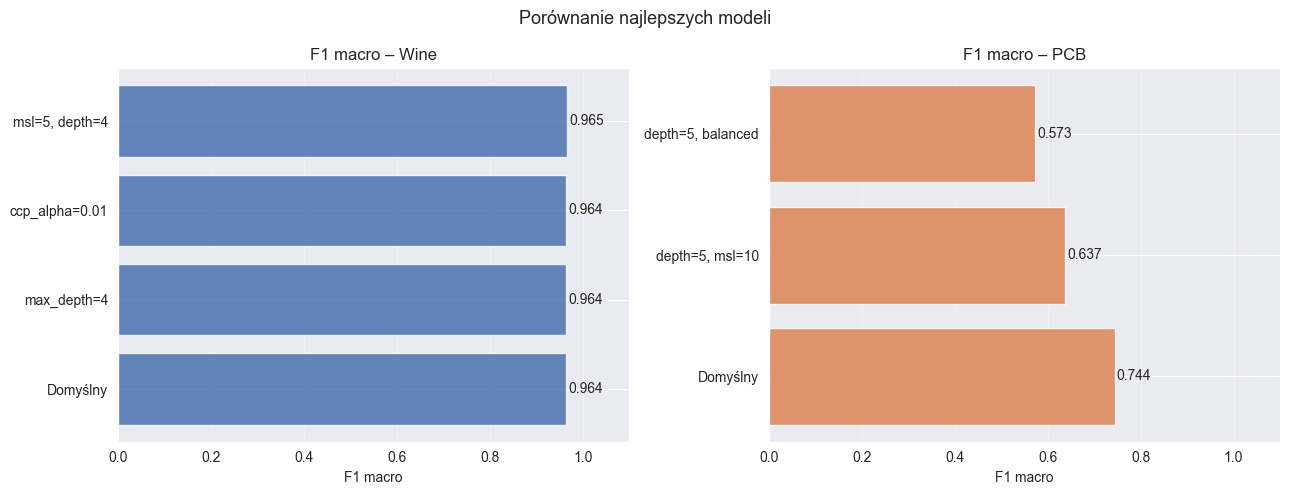

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, zb, color in zip(
    axes, ['Wine', 'PCB'], ['#4C72B0', '#DD8452']
):
    sub = df_summary[df_summary['Zbiór'] == zb]
    f1_vals = sub['F1 macro'].astype(float)
    bars = ax.barh(sub['Konfiguracja'], f1_vals, color=color, alpha=0.85)
    for bar, val in zip(bars, f1_vals):
        ax.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height()/2,
                f'{val:.3f}', va='center', fontsize=10)
    ax.set_xlim(0, 1.1)
    ax.set_xlabel('F1 macro')
    ax.set_title(f'F1 macro – {zb}')
    ax.grid(axis='x', alpha=0.3)

plt.suptitle('Porównanie najlepszych modeli', fontsize=13)
plt.tight_layout()
plt.show()


## Wnioski końcowe

### Wine
Algorytm CART osiąga doskonałe wyniki na zbiorze Wine. **Model domyślny jest przeuczony** – pełna accuracy treningowa i gorsza testowa. Najlepsze wyniki daje ograniczenie głębokości do **max_depth=4** lub przycinanie **ccp_alpha~=0.01**, które redukują drzewo bez utraty jakości. Stratyfikacja nie zmienia istotnie wyników (klasy są zbalansowane).

### Polish Companies Bankruptcy
PCB to trudniejszy problem ze względu na **silne niezbalansowanie klas (~20:1)**. Model bez ważenia osiąga wysoką accuracy, ale ignoruje klasę mniejszościową. Kluczowe ustalenia:
- **Strojenie**: `max_depth=5, min_samples_leaf=10` daje dobry balans między złożonością a generalizacją.
- **Stratyfikacja**: Niezbędna przy walidacji krzyżowej – zwykły KFold daje niestabilne wyniki.
- **Wagi klas**: `class_weight='balanced'` drastycznie poprawia recall bankrutów (priorytet biznesowy), akceptując niższą precision.

### Ogólne wnioski o algorytmie CART
CART jest prostym, interpretowalnym algorytmem, ale bez regularyzacji podatnym na overfitting. Hiperparametry `max_depth`, `min_samples_leaf` i `ccp_alpha` są efektywnymi narzędziami kontroli złożoności. Dla niezbalansowanych zbiorów `class_weight` jest niezbędnym elementem konfiguracji.


## Odpowiedzi na pytania pomocnicze

**1. Co znajduje się w liściach drzewa?**

W liściach drzewa decyzyjnego znajduje się **rozkład próbek treningowych** należących do danego węzła (ile próbek, jakie klasy) oraz **przewidywana klasa** – ta z największą liczbą próbek lub (przy wagowaniu) z najwyższą ważoną reprezentacją. Dodatkowo wyświetlana jest wartość współczynnika Giniego (lub entropii) dla danego węzła.


**2. Czy przycinanie drzewa (pruning) jest potrzebne? Na czym polega?**

Tak, pruning jest **zwykle potrzebny**. Bez przycinania drzewo może rosnąć do momentu, gdy każdy liść zawiera tylko jedną klasę (gini=0), co prowadzi do overfittingu. **Cost-complexity pruning** (`ccp_alpha`) polega na iteracyjnym usuwaniu węzłów, które wnoszą najmniejszy wkład w zmniejszenie błędów w przeliczeniu na rozmiar drzewa. Im wyższa wartość `ccp_alpha`, tym agresywniejsze przycinanie.



**3. Czy drzewo może być za duże lub za małe? Co to znaczy?**

- **Za duże (overfitting)**: Drzewo zapamiętuje dane treningowe – 100% acc. na treningu, ale słabo generalizuje. Zbyt wiele liści/głębokości.
- **Za małe (underfitting)**: Drzewo jest zbyt uproszczone – nie uchwyca wzorców w danych. Zbyt mała głębokość lub zbyt duże `min_samples_leaf`.



**4. Czy drzewo decyzyjne potrzebuje normalizacji/standaryzacji/dyskretyzacji danych?**

**Nie**. Drzewa decyzyjne są odporne na skalę cech – każdy podział bazuje na porównaniu z progiem dla jednej cechy, więc absolutne wartości i skala nie mają znaczenia. Standaryzacja ani normalizacja nie zmieniają struktury drzewa.



**5. Czy model można przeuczyć? Czym się to objawia?**

**Tak** – to jeden z głównych problemów drzew decyzyjnych. Objawia się:
- Bardzo wysoką accuracy na zbiorze treningowym (często 100%)
- Znaczącym spadkiem accuracy na zbiorze testowym
- Bardzo głębokim drzewem z wieloma liściami

Rozwiązanie: ograniczenie głębokości (`max_depth`), wymaganie minimalnej liczby próbek w liściu (`min_samples_leaf`) lub przycinanie (`ccp_alpha`).



**6. Na czym polega wagowanie klas?**

Wagowanie klas (`class_weight`) modyfikuje funkcję kosztu modelu tak, aby błędy na klasie mniejszościowej były **bardziej karane**. Przy `class_weight='balanced'` wagi są automatycznie odwrotnie proporcjonalne do liczebności klas. W praktyce powoduje to, że model poświęca więcej uwagi rzadkim przykładom (np. bankrutom), co zwiększa recall dla klasy mniejszościowej kosztem precision i accuracy.